# 06 — Tầng 8: Market Shock, Stress Testing và Change-Point

**Vị trí trong pipeline** (`../docs/reports/agent1_implementation_review.md` Tầng 8):
```
04_conformal_calibration → 05_monte_carlo_cash_in → [06_stress_testing_regime_detection] → 07_backtesting_evaluation → 08_discrete_time_survival
```

**Câu hỏi tầng này trả lời:** *"Nếu thị trường xấu đi, công ty chịu được đến đâu?"*

Notebook 05 đã cho dải dòng tiền **base**. Nhưng dải đó chỉ mô tả sự bất định mà model
**nhìn thấy được từ dữ liệu quá khứ**. Nó không trả lời được câu hỏi "nếu mọi khách hàng
đồng loạt trả chậm thêm 30 ngày thì sao" — vì trong dữ liệu train chưa từng có cú sốc đó ở
mức đủ mạnh để model học.

**Nhiệm vụ:**
1. Chạy 11 kịch bản stress **tất định** trên đúng pool đang mở, gồm 1 kịch bản được hiệu
   chỉnh từ cú sốc có thật trong dữ liệu.
2. Đo **PSI** giữa pool train và pool đang mở — bằng chứng định lượng cho P0-1.
3. **Change-point detection** trên hành vi thanh toán theo tuần, không dùng thư viện ngoài.
4. Kết luận **regime hiện tại** (normal / drift warning / crisis) kèm hành động bắt buộc.

> **Phát hiện lớn nhất của notebook này:** dữ liệu chứa một điểm gãy chế độ rõ rệt vào
> **tuần 2020-03-14**. Trung vị số ngày trả trễ nhảy từ 0 lên 5→15 ngày, tỷ lệ trả trễ từ
> ~40% lên ~87%. Model hiện tại được train chủ yếu trên giai đoạn trước điểm gãy, rồi đem
> dự báo cho pool nằm hoàn toàn sau điểm gãy.

## 📋 Decision Log (D33 → D38)

---

### D33 · Stress tất định phải tách khỏi Monte Carlo base

Plan Tầng 8 nói rõ và ta giữ nguyên: *"không gọi deterministic stress là xác suất"*.

| | Monte Carlo base (05) | Stress scenario (06) |
|---|---|---|
| Câu hỏi | "Phân phối dòng tiền là gì?" | "Nếu điều X xảy ra thì sao?" |
| Đọc kết quả | xác suất | **what-if**, không có xác suất kèm theo |
| Nguồn bất định | residual quá khứ + copula | giả định do người ra quyết định đặt |
| Nhãn bắt buộc | `base forecast` | `stress scenario` |

Trộn hai thứ này là lỗi trình bày nghiêm trọng: nó biến một giả định thành một xác suất.

---

### D34 · Danh mục kịch bản và cách hiện thực

Mỗi kịch bản là một **phép biến đổi trên ma trận ngày trả** của cùng bộ mô phỏng, nên mọi so
sánh đều dùng chung cấu trúc phụ thuộc và chung seed (so sánh theo cặp).

| ID | Kịch bản | Hiện thực |
|---|---|---|
| S0 | Base | không đổi |
| S1a/b/c | Toàn bộ khách trả chậm thêm 15 / 30 / 60 ngày | `days += k` |
| S2a/b | Top-1 / Top-3 khách hàng lớn nhất không trả trong kỳ | `days := ∞` cho nhóm đó |
| S2c | **Toàn bộ nhóm "WAL-MAR *" không trả** | `days := ∞`; xem lý do bên dưới |
| S3 | Hoá đơn đang quá hạn trễ thêm 30 ngày | `days[overdue] += 30` |
| S4a/b | Haircut −20% / −30% trên P10 | phép toán trên kết quả, không phải mô phỏng |
| S5 | **Cú sốc đo được từ chính dữ liệu (2020-03)** | `days += Δ` với Δ lấy từ §5 |
| S6 | Kịch bản kép: S1b + S3 + S2b | cộng dồn |

S2c có lý do dữ liệu: notebook 05 phát hiện 11 pháp nhân `WAL-MAR *` đứng riêng theo
`customer_id` nhưng chiếm 18,4% dư nợ. Nếu chúng thuộc cùng một tập đoàn thì đây là rủi ro
tập trung lớn nhất trong sổ, và nó **không** xuất hiện trong bảng top khách hàng.

S5 là kịch bản có giá trị nhất trong danh mục: nó không do ta bịa ra mà là **biên độ cú sốc
thật đã xảy ra trong chính dữ liệu này**.

---

### D35 · Change-point: binary segmentation + chi phí L2, không dùng `ruptures`

`offline_change_point_detection_review.pdf` mô tả bài toán theo 3 thành phần: cost function, search method, constraint.
Ta hiện thực trực tiếp:

- **Cost**: L2 — tổng bình phương độ lệch quanh trung bình từng đoạn.
- **Search**: binary segmentation (tham lam, đệ quy) — `O(n²)` với n=73 tuần, chạy tức thì.
- **Constraint**: penalty kiểu BIC trên chuỗi đã chuẩn hoá; đoạn tối thiểu 4 tuần.

Vì sao không cài `ruptures`: một dependency ngoài cho ~40 dòng thuật toán làm hồ sơ khó tái
lập hơn, và ta cần biết chính xác penalty đang dùng để trả lời hội đồng. §5b có bảng độ nhạy
theo penalty để chứng minh kết luận không phụ thuộc vào một lựa chọn tuỳ tiện.

---

### D36 · Chuỗi cuối kỳ bị **right-truncation** — không được đọc thẳng

Chuỗi "tiền thu theo tuần" sụp đổ ở các tuần cuối. Một phần là hành vi thật, nhưng một phần
lớn là **thiên lệch quan sát**: hoá đơn phát hành gần ngày kết thúc dữ liệu mà chưa được trả
thì không xuất hiện trong chuỗi. 9.681 hoá đơn đang mở chính là phần bị cắt mất.

Vì vậy:
- Chuỗi **hành vi** (`trung vị days_late`, `tỷ lệ trả trễ`) tính trên hoá đơn đã trả → dùng
  được để phát hiện điểm gãy, nhưng cũng lệch lạc quan (hoá đơn trễ nhất chưa được quan sát).
- Chuỗi **tiền thu** → chỉ dùng để minh hoạ, **không** dùng làm bằng chứng chính.
- Kết luận regime phải dựa thêm vào PSI (§4) — chỉ số này không bị truncation vì nó so sánh
  đặc trưng *tại thời điểm quan sát*, không cần biết kết quả.

---

### D37 · Ngưỡng PSI

Quy ước công nghiệp: `PSI < 0,10` ổn định; `0,10–0,25` dịch chuyển vừa; `> 0,25` dịch chuyển
lớn, phải xem lại model. Ta dùng đúng quy ước này và ghi rõ nó là **quy ước**, không phải
kiểm định thống kê có p-value.

---

### D38 · Luật bật crisis mode

Regime được quyết bằng 3 tín hiệu độc lập, không phải bằng cảm nhận:

| Tín hiệu | Ngưỡng |
|---|---|
| PSI tối đa trên feature quan trọng | > 0,25 |
| Điểm gãy chế độ trong 8 tuần gần nhất | có |
| Coverage dải cash trên test (notebook 05) | < 75% |

`crisis` khi ≥2 tín hiệu bật; `drift warning` khi 1 tín hiệu; `normal` khi không có.
Hành động bắt buộc theo từng regime nằm ở §6 và được ghi vào `regime_status.csv` để
dashboard (notebook 10) hiển thị.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.special import erf

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 210)
pd.set_option("display.float_format", "{:,.3f}".format)

BASE = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "notebooks").is_dir() and (parent / ".gitignore").is_file()
)
PROC = BASE / "data" / "processed"

IN_LIVE = PROC / "cqr_current_forecast.csv"
IN_RESID = PROC / "cqr_residuals_calibration.csv"
IN_CLEAN = PROC / "invoices_ar_clean.csv"
IN_SNAP_FEAT = PROC / "rolling_snapshot_features.csv"
IN_LIVE_FEAT = PROC / "current_open_invoice_features.csv"
IN_SHORTFALL = PROC / "mc_shortfall_report.csv"
IN_DAILY = PROC / "mc_daily_cash_forecast.csv"

OUT_SCENARIOS = PROC / "stress_scenario_summary.csv"
OUT_CURVES = PROC / "stress_daily_curves.csv"
OUT_PSI = PROC / "psi_train_vs_live.csv"
OUT_CP = PROC / "changepoint_segments.csv"
OUT_REGIME = PROC / "regime_status.csv"

HORIZON_DAYS = 91
WEEKS = HORIZON_DAYS // 7
HORIZONS = [30, 60, 90]
N_SIMS = 4_000            # ít hơn 05 vì phải chạy 11 kịch bản; so sánh theo cặp cùng seed
SIM_BATCH = 250
DAY_FLOOR = 1.0
SEED = 42
BLOCK_DAY = 10_000        # "không trả trong kỳ" = đẩy ra ngoài mọi horizon
PSI_WARN, PSI_ALERT = 0.10, 0.25          # D37
CP_MIN_SEG, CP_MAX_BKPS = 4, 5            # D35
CP_RECENT_WEEKS = 8                       # D38

C_SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
C_GOOD, C_WARN, C_SERIOUS, C_CRIT = "#0ca30c", "#fab219", "#ec835a", "#d03b3b"
C_INK, C_INK2, C_GRID = "#0b0b0b", "#52514e", "#d8d7d2"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": C_GRID, "axes.labelcolor": C_INK2, "axes.titlecolor": C_INK,
    "xtick.color": C_INK2, "ytick.color": C_INK2, "text.color": C_INK,
    "grid.color": C_GRID, "grid.linewidth": 0.8, "axes.grid": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
print("Config OK")

Config OK


## 1. Load dữ liệu và dựng lại bộ máy mô phỏng

Bộ máy mô phỏng được **chép lại nguyên vẹn** từ notebook 05 (cùng copula, cùng sampler, cùng
tham số ρ đã chọn trên validation) để notebook này chạy độc lập được. Mọi thay đổi ở 05 phải
đồng bộ sang đây — đây là chi phí có ý thức của việc giữ mỗi notebook tự chạy được.

In [2]:
live = pd.read_csv(IN_LIVE, parse_dates=["cutoff_date", "issue_date", "due_date"])
resid = pd.read_csv(IN_RESID)
clean = pd.read_csv(IN_CLEAN, parse_dates=["issue_date", "due_date", "paid_date"])
shortfall_base = pd.read_csv(IN_SHORTFALL)

LIVE_CUTOFF = live["cutoff_date"].iloc[0]
RHO_C = float(shortfall_base["rho_cust"].iloc[0])
RHO_M = float(shortfall_base["rho_market"].iloc[0])
SAMPLER = str(shortfall_base["sampler"].iloc[0])
PLAN_WEEKLY = float(shortfall_base["plan_weekly_usd"].iloc[0])
PLAN_DAILY = PLAN_WEEKLY / 7.0

print(f"Pool đang mở : {len(live):,} hoá đơn | ${live['amount'].sum():,.0f} | cutoff {LIVE_CUTOFF.date()}")
print(f"Tham số MC kế thừa từ notebook 05: sampler={SAMPLER}, ρ_c={RHO_C}, ρ_m={RHO_M}")
print(f"Ngưỡng kế hoạch proxy: ${PLAN_WEEKLY:,.0f}/tuần")


def norm_cdf(z):
    return 0.5 * (1.0 + erf(z / np.sqrt(2.0, dtype=np.float32)))


def make_uniforms(n_inv, cust_codes, n_cust, rho_c, rho_m, batch, rng):
    w_i = np.sqrt(max(1.0 - rho_c - rho_m, 0.0), dtype=np.float32)
    z = w_i * rng.standard_normal((n_inv, batch), dtype=np.float32)
    if rho_c > 0:
        z += np.float32(np.sqrt(rho_c)) * rng.standard_normal((n_cust, batch), dtype=np.float32)[cust_codes]
    if rho_m > 0:
        z += np.float32(np.sqrt(rho_m)) * rng.standard_normal((1, batch), dtype=np.float32)
    return np.clip(norm_cdf(z), 1e-6, 1 - 1e-6)


def bootstrap_from_u(u, center, groups, pools, floor=DAY_FLOOR, min_pool=100):
    out = np.empty_like(u)
    for g in np.unique(groups):
        m = groups == g
        pool = pools.get(g, pools["__global__"])
        if len(pool) < min_pool:
            pool = pools["__global__"]
        idx = np.clip((u[m] * len(pool)).astype(np.int32), 0, len(pool) - 1)
        out[m] = center[m, None] + pool[idx]
    return np.maximum(out, floor)


POOLS = {g: np.sort(p["residual_days"].to_numpy(np.float32)) for g, p in resid.groupby("cal_group")}
POOLS["__global__"] = np.sort(resid["residual_days"].to_numpy(np.float32))

CODES, UNIQ = pd.factorize(live["customer_id"])
CODES = CODES.astype(np.int32)
N_CUST = len(UNIQ)
GROUPS = live["cal_group"].to_numpy()
CENTER = live["cal_q50"].to_numpy(np.float32)
AMOUNTS = live["amount"].to_numpy(float)


def base_days(batch, rng):
    u = make_uniforms(len(live), CODES, N_CUST, RHO_C, RHO_M, batch, rng)
    return bootstrap_from_u(u, CENTER, GROUPS, POOLS)


def simulate(day_fn, n_sims=N_SIMS, seed=SEED, horizon=HORIZON_DAYS, batch=SIM_BATCH):
    """Trả daily (horizon × n_sims) và prob trả trong từng horizon."""
    rng = np.random.default_rng(seed)
    daily = np.zeros((horizon, n_sims))
    paid = {h: np.zeros(len(AMOUNTS)) for h in HORIZONS}
    done = 0
    while done < n_sims:
        b = min(batch, n_sims - done)
        days = day_fn(b, rng)
        idx = np.ceil(days).astype(np.int64)
        for h in HORIZONS:
            paid[h] += (idx <= h).sum(axis=1)
        inside = idx <= horizon
        sim = np.broadcast_to(np.arange(b, dtype=np.int64), idx.shape)
        w = np.broadcast_to(AMOUNTS[:, None], idx.shape)
        flat = ((idx - 1) * b + sim)[inside].ravel()
        daily[:, done:done + b] = np.bincount(
            flat, weights=w[inside].ravel(), minlength=horizon * b).reshape(horizon, b)
        done += b
    return daily, {h: paid[h] / n_sims for h in HORIZONS}


print("Engine sẵn sàng (bản sao của notebook 05).")

Pool đang mở : 9,681 hoá đơn | $312,538,769 | cutoff 2020-05-22
Tham số MC kế thừa từ notebook 05: sampler=bootstrap, ρ_c=0.25, ρ_m=0.75
Ngưỡng kế hoạch proxy: $729,069/tuần
Engine sẵn sàng (bản sao của notebook 05).


## 2. Định nghĩa 11 kịch bản (D34)

In [3]:
overdue_mask = live["is_overdue_at_T"].to_numpy() == 1
amount_by_cust = live.groupby("customer_id")["amount"].sum().sort_values(ascending=False)
top1 = set(amount_by_cust.index[:1])
top3 = set(amount_by_cust.index[:3])
walmart_mask = live["name_customer"].astype("string").str.startswith("WAL-MAR", na=False).to_numpy()
top1_mask = live["customer_id"].isin(top1).to_numpy()
top3_mask = live["customer_id"].isin(top3).to_numpy()


def scenario_fn(delay_all=0.0, delay_mask=None, delay_mask_days=0.0, block_mask=None):
    """Bọc base_days bằng một phép biến đổi tất định (D34)."""
    def fn(batch, rng):
        d = base_days(batch, rng)
        if delay_all:
            d = d + delay_all
        if delay_mask is not None and delay_mask_days:
            d[delay_mask] = d[delay_mask] + delay_mask_days
        if block_mask is not None:
            d[block_mask] = BLOCK_DAY
        return d
    return fn


SCENARIOS = [
    ("S0", "Base forecast", "base", scenario_fn()),
    ("S1a", "Mọi khách trả chậm +15 ngày", "delay", scenario_fn(delay_all=15)),
    ("S1b", "Mọi khách trả chậm +30 ngày", "delay", scenario_fn(delay_all=30)),
    ("S1c", "Mọi khách trả chậm +60 ngày", "delay", scenario_fn(delay_all=60)),
    ("S2a", f"Top-1 khách hàng không trả ({amount_by_cust.index[0]})", "default",
     scenario_fn(block_mask=top1_mask)),
    ("S2b", "Top-3 khách hàng không trả", "default", scenario_fn(block_mask=top3_mask)),
    ("S2c", "Toàn bộ nhóm WAL-MAR không trả", "concentration", scenario_fn(block_mask=walmart_mask)),
    ("S3", "Hoá đơn đang quá hạn trễ thêm 30 ngày", "delay",
     scenario_fn(delay_mask=overdue_mask, delay_mask_days=30)),
]

print(f"{'ID':<5}{'Kịch bản':<48}{'Số hoá đơn ảnh hưởng':>22}{'Dư nợ ảnh hưởng':>20}")
for mask, label in [(top1_mask, "S2a top-1"), (top3_mask, "S2b top-3"),
                    (walmart_mask, "S2c WAL-MAR"), (overdue_mask, "S3 overdue")]:
    print(f"{'':<5}{label:<48}{mask.sum():>22,}{AMOUNTS[mask].sum():>20,.0f}")

ID   Kịch bản                                          Số hoá đơn ảnh hưởng     Dư nợ ảnh hưởng
     S2a top-1                                                        2,602          57,516,597
     S2b top-3                                                        3,155          86,736,291
     S2c WAL-MAR                                                      2,602          57,516,597
     S3 overdue                                                       9,181         301,765,667


## 3. Chạy stress và tổng hợp

In [4]:
def summarize(daily, name, sid, kind):
    cum = np.cumsum(daily, axis=0)
    row = {"scenario_id": sid, "scenario": name, "kind": kind}
    for h in HORIZONS:
        row[f"cash_{h}d_p10"] = float(np.percentile(cum[h - 1], 10))
        row[f"cash_{h}d_p50"] = float(np.percentile(cum[h - 1], 50))
        row[f"cash_{h}d_mean"] = float(cum[h - 1].mean())
    plan_cum = PLAN_DAILY * np.arange(1, HORIZON_DAYS + 1)
    p10 = np.percentile(cum, 10, axis=1)
    below = np.where(p10 < plan_cum)[0]
    run, first = 0, None
    for i in range(len(p10)):
        run = run + 1 if p10[i] < plan_cum[i] else 0
        if run >= 5:
            first = int(i - 3)
            break
    row["first_day_p10_below_plan"] = first
    row["days_p10_below_plan"] = int(len(below))
    row["max_gap_p10_usd"] = float(np.max(plan_cum - p10)) if len(below) else 0.0
    return row, cum


results, curves = [], {}
for sid, name, kind, fn in SCENARIOS:
    daily, _ = simulate(fn)
    row, cum = summarize(daily, name, sid, kind)
    results.append(row)
    curves[sid] = {"p10": np.percentile(cum, 10, axis=1), "p50": np.percentile(cum, 50, axis=1)}
    print(f"  {sid:<5} {name:<46} cash30d P50 = ${row['cash_30d_p50']/1e6:>7.1f}M")

# ── S6: kịch bản kép ─────────────────────────────────────────────────────
combo = scenario_fn(delay_all=30, delay_mask=overdue_mask, delay_mask_days=30, block_mask=top3_mask)
daily, _ = simulate(combo)
row, cum = summarize(daily, "Kép: +30 ngày & overdue +30 & top-3 không trả", "S6", "combined")
results.append(row)
curves["S6"] = {"p10": np.percentile(cum, 10, axis=1), "p50": np.percentile(cum, 50, axis=1)}
print(f"  {'S6':<5} {'Kịch bản kép':<46} cash30d P50 = ${row['cash_30d_p50']/1e6:>7.1f}M")

stress = pd.DataFrame(results)
base_row = stress[stress["scenario_id"] == "S0"].iloc[0]
for h in HORIZONS:
    stress[f"delta_{h}d_vs_base_pct"] = (stress[f"cash_{h}d_p50"] - base_row[f"cash_{h}d_p50"]) / base_row[f"cash_{h}d_p50"]

  S0    Base forecast                                  cash30d P50 = $  312.0M


  S1a   Mọi khách trả chậm +15 ngày                    cash30d P50 = $  206.5M


  S1b   Mọi khách trả chậm +30 ngày                    cash30d P50 = $    0.0M


  S1c   Mọi khách trả chậm +60 ngày                    cash30d P50 = $    0.0M


  S2a   Top-1 khách hàng không trả (200769623)         cash30d P50 = $  254.5M


  S2b   Top-3 khách hàng không trả                     cash30d P50 = $  225.4M


  S2c   Toàn bộ nhóm WAL-MAR không trả                 cash30d P50 = $  254.5M


  S3    Hoá đơn đang quá hạn trễ thêm 30 ngày          cash30d P50 = $   10.4M


  S6    Kịch bản kép                                   cash30d P50 = $    0.0M


### 3b. Haircut trên P10 (S4) — phép toán, không phải mô phỏng

Plan yêu cầu kịch bản "cash-in P10 giảm thêm 20–30%". Đây **không** phải một giả thiết về
hành vi khách hàng mà là một biên an toàn do CFO áp lên con số báo cáo, nên phải trình bày
tách bạch khỏi các kịch bản mô phỏng.

In [5]:
haircut_rows = []
for hc in (0.20, 0.30):
    r = {"scenario_id": f"S4_{int(hc*100)}", "scenario": f"Haircut −{int(hc*100)}% trên P10",
         "kind": "policy_haircut"}
    for h in HORIZONS:
        r[f"cash_{h}d_p10"] = base_row[f"cash_{h}d_p10"] * (1 - hc)
        r[f"cash_{h}d_p50"] = base_row[f"cash_{h}d_p50"]
        r[f"cash_{h}d_mean"] = base_row[f"cash_{h}d_mean"]
    plan_30 = PLAN_DAILY * 30
    r["first_day_p10_below_plan"] = None
    r["days_p10_below_plan"] = None
    r["max_gap_p10_usd"] = max(0.0, plan_30 - r["cash_30d_p10"])
    haircut_rows.append(r)

stress = pd.concat([stress, pd.DataFrame(haircut_rows)], ignore_index=True)

show = ["scenario_id", "scenario", "kind", "cash_30d_p10", "cash_30d_p50",
        "cash_90d_p50", "delta_30d_vs_base_pct", "first_day_p10_below_plan"]
print("BẢNG STRESS TEST — dòng tiền thu từ AR đang mở (USD)")
print(stress[show].to_string(index=False))
print()
print(f"Tổng dư nợ đang mở: ${AMOUNTS.sum():,.0f}")
print(f"Ngưỡng kế hoạch 30 ngày (proxy): ${PLAN_DAILY*30:,.0f}")

BẢNG STRESS TEST — dòng tiền thu từ AR đang mở (USD)
scenario_id                                      scenario           kind    cash_30d_p10    cash_30d_p50    cash_90d_p50  delta_30d_vs_base_pct first_day_p10_below_plan
         S0                                 Base forecast           base 272,219,100.177 312,046,577.705 312,538,768.520                  0.000                      NaN
        S1a                   Mọi khách trả chậm +15 ngày          delay  41,890,584.949 206,517,906.000 312,538,768.520                 -0.338                    1.000
        S1b                   Mọi khách trả chậm +30 ngày          delay           0.000           0.000 312,538,768.520                 -1.000                    1.000
        S1c                   Mọi khách trả chậm +60 ngày          delay           0.000           0.000 312,046,577.705                 -1.000                    1.000
        S2a        Top-1 khách hàng không trả (200769623)        default 222,035,609.906 254,531,730.0

### 3c. Đọc kết quả stress

In [6]:
s6 = stress[stress["scenario_id"] == "S6"].iloc[0]
s2a = stress[stress["scenario_id"] == "S2a"].iloc[0]
s2c = stress[stress["scenario_id"] == "S2c"].iloc[0]

print("Ba con số cho slide CFO:")
print(f"  1. Base 30 ngày (P50)                       : ${base_row['cash_30d_p50']:,.0f}")
print(f"  2. Kịch bản kép S6, 30 ngày (P50)           : ${s6['cash_30d_p50']:,.0f} "
      f"({s6['delta_30d_vs_base_pct']:+.1%})")
print(f"  3. Thiếu hụt lớn nhất so kế hoạch (mọi KB)  : ${stress['max_gap_p10_usd'].max():,.0f}")
print()

print("(a) Vì sao S1b/S1c cho cash 30 ngày = $0 — và vì sao đó KHÔNG phải bug:")
print(f"    Sàn dự báo là 1 ngày (D23), nên cộng thêm 30 ngày thì mọi hoá đơn rơi vào ngày ≥ 31.")
print("    Kịch bản 'toàn bộ khách trả chậm thêm 30 ngày' theo nghĩa đen làm rỗng cửa sổ 30 ngày.")
print("    Vì vậy với nhóm kịch bản delay phải đọc ở mốc 60/90 ngày, không phải mốc 30 ngày:")
delay_view = stress[stress["scenario_id"].isin(["S0", "S1a", "S1b", "S1c", "S3"])][
    ["scenario_id", "cash_30d_p50", "cash_60d_p50", "cash_90d_p50"]]
print(delay_view.to_string(index=False))
print()

print("(b) Rủi ro tập trung:")
same = abs(s2a["cash_30d_p50"] - s2c["cash_30d_p50"]) < 1.0
print(f"    S2a (top-1 theo customer_id) và S2c (gộp theo tên 'WAL-MAR *') cho kết quả "
      f"{'TRÙNG KHÍT' if same else 'khác nhau'}.")
if same:
    print(f"    → Toàn bộ các biến thể tên đó thuộc CÙNG MỘT customer_id: "
          f"${AMOUNTS[walmart_mask].sum():,.0f} = {AMOUNTS[walmart_mask].sum()/AMOUNTS.sum():.1%} dư nợ")
    print("      nằm ở một khách hàng duy nhất. Nếu bảng rủi ro gộp theo tên, mức tập trung này")
    print("      bị chia nhỏ và biến mất — đây là lỗi trình bày đủ để CFO đánh giá sai sổ AR.")
print()

print("(c) So với ngưỡng kế hoạch proxy:")
breach = stress[(stress["kind"] != "policy_haircut") & stress["first_day_p10_below_plan"].notna()]
if len(breach):
    print(f"    {len(breach)}/{(stress['kind'] != 'policy_haircut').sum()} kịch bản tạo ra thiếu hụt "
          f"kéo dài ở nhánh P10: {', '.join(breach['scenario_id'])}")
    print(f"    Sớm nhất: ngày thứ {int(breach['first_day_p10_below_plan'].min())} kể từ cutoff.")
else:
    print("    Không kịch bản nào tạo ra thiếu hụt kéo dài ở nhánh P10.")
print(f"    Ngưỡng proxy chỉ ${PLAN_DAILY*30:,.0f} cho 30 ngày, tức {PLAN_DAILY*30/AMOUNTS.sum():.1%} quy mô sổ AR.")
print("    Ngưỡng thấp như vậy vì nó lấy từ 13 tuần cuối — đúng giai đoạn dòng tiền đã sụp sau cú")
print("    sốc tháng 3/2020. Đây là hạn chế của proxy (D30), KHÔNG phải bằng chứng công ty an toàn.")

Ba con số cho slide CFO:
  1. Base 30 ngày (P50)                       : $312,046,578
  2. Kịch bản kép S6, 30 ngày (P50)           : $0 (-100.0%)
  3. Thiếu hụt lớn nhất so kế hoạch (mọi KB)  : $6,457,473

(a) Vì sao S1b/S1c cho cash 30 ngày = $0 — và vì sao đó KHÔNG phải bug:
    Sàn dự báo là 1 ngày (D23), nên cộng thêm 30 ngày thì mọi hoá đơn rơi vào ngày ≥ 31.
    Kịch bản 'toàn bộ khách trả chậm thêm 30 ngày' theo nghĩa đen làm rỗng cửa sổ 30 ngày.
    Vì vậy với nhóm kịch bản delay phải đọc ở mốc 60/90 ngày, không phải mốc 30 ngày:
scenario_id    cash_30d_p50    cash_60d_p50    cash_90d_p50
         S0 312,046,577.705 312,538,768.520 312,538,768.520
        S1a 206,517,906.000 312,519,153.510 312,538,768.520
        S1b           0.000 312,046,577.705 312,538,768.520
        S1c           0.000           0.000 312,046,577.705
         S3  10,417,987.850 312,416,580.895 312,538,768.520

(b) Rủi ro tập trung:
    S2a (top-1 theo customer_id) và S2c (gộp theo tên 'WAL-MAR *') cho k

## 4. Biểu đồ kịch bản

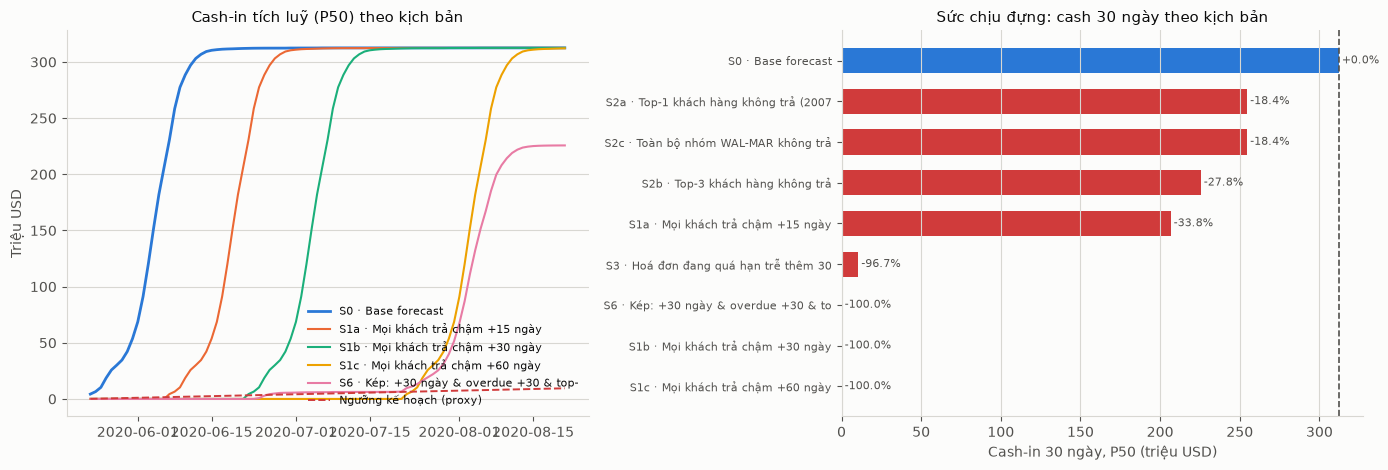

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
dates = pd.date_range(LIVE_CUTOFF + pd.Timedelta(days=1), periods=HORIZON_DAYS)

ax = axes[0]
plot_ids = ["S0", "S1a", "S1b", "S1c", "S6"]
for i, sid in enumerate(plot_ids):
    lbl = stress.loc[stress["scenario_id"] == sid, "scenario"].iloc[0]
    ax.plot(dates, curves[sid]["p50"] / 1e6, lw=2 if sid == "S0" else 1.5,
            color=C_SERIES[i % len(C_SERIES)], label=f"{sid} · {lbl[:34]}")
ax.plot(dates, PLAN_DAILY * np.arange(1, HORIZON_DAYS + 1) / 1e6,
        color=C_CRIT, ls="--", lw=1.4, label="Ngưỡng kế hoạch (proxy)")
ax.set_ylabel("Triệu USD"); ax.set_title("Cash-in tích luỹ (P50) theo kịch bản")
ax.legend(fontsize=8, loc="lower right"); ax.grid(axis="x", visible=False)

ax = axes[1]
sim_only = stress[stress["kind"] != "policy_haircut"].sort_values("cash_30d_p50")
y = np.arange(len(sim_only))
colors = [C_SERIES[0] if s == "S0" else (C_CRIT if d < -0.15 else C_SERIOUS)
          for s, d in zip(sim_only["scenario_id"], sim_only["delta_30d_vs_base_pct"])]
ax.barh(y, sim_only["cash_30d_p50"] / 1e6, color=colors, height=0.62)
ax.set_yticks(y)
ax.set_yticklabels([f"{s} · {n[:32]}" for s, n in zip(sim_only["scenario_id"], sim_only["scenario"])],
                   fontsize=8)
ax.axvline(base_row["cash_30d_p50"] / 1e6, color=C_INK2, ls="--", lw=1.2)
for yi, (v, d) in enumerate(zip(sim_only["cash_30d_p50"], sim_only["delta_30d_vs_base_pct"])):
    ax.text(v / 1e6 + 2, yi, f"{d:+.1%}", va="center", fontsize=8, color=C_INK2)
ax.set_xlabel("Cash-in 30 ngày, P50 (triệu USD)")
ax.set_title("Sức chịu đựng: cash 30 ngày theo kịch bản")
ax.grid(axis="y", visible=False)

plt.tight_layout(); plt.show()

## 5. PSI — bằng chứng định lượng cho lệch phân bố train/live (P0-1)

PSI không cần biết nhãn nên **không** bị right-truncation (D36). Đây là tín hiệu drift đáng
tin nhất ta có tại thời điểm dự báo.

In [8]:
PSI_FEATURES = ["days_past_due_at_T", "days_until_due_at_T", "observed_age_days",
                "amount_log1p", "customer_median_delay_hist",
                "customer_recency_delay_median_hist", "customer_invoice_count_hist",
                "customer_last_paid_age_days"]

train_feat = pd.read_csv(IN_SNAP_FEAT, usecols=PSI_FEATURES + ["time_split", "aging_bucket_at_T"],
                         low_memory=False)
train_feat = train_feat[train_feat["time_split"] == "train"]
live_feat = pd.read_csv(IN_LIVE_FEAT, usecols=PSI_FEATURES + ["aging_bucket_at_T"], low_memory=False)


def psi_numeric(expected, actual, bins=10):
    """PSI với bin theo phân vị của tập expected; nhóm rỗng được làm mượt."""
    e = pd.to_numeric(expected, errors="coerce").dropna().to_numpy(float)
    a = pd.to_numeric(actual, errors="coerce").dropna().to_numpy(float)
    edges = np.unique(np.quantile(e, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    e_pct = np.histogram(e, edges)[0] / len(e)
    a_pct = np.histogram(a, edges)[0] / len(a)
    eps = 1e-6
    e_pct, a_pct = np.maximum(e_pct, eps), np.maximum(a_pct, eps)
    return float(np.sum((a_pct - e_pct) * np.log(a_pct / e_pct)))


def psi_categorical(expected, actual):
    cats = sorted(set(expected.dropna().astype(str)) | set(actual.dropna().astype(str)))
    e = expected.astype(str).value_counts(normalize=True).reindex(cats).fillna(0).to_numpy()
    a = actual.astype(str).value_counts(normalize=True).reindex(cats).fillna(0).to_numpy()
    eps = 1e-6
    e, a = np.maximum(e, eps), np.maximum(a, eps)
    return float(np.sum((a - e) * np.log(a / e)))


psi_rows = []
for f in PSI_FEATURES:
    val = psi_numeric(train_feat[f], live_feat[f])
    psi_rows.append({"feature": f, "psi": val,
                     "train_median": float(pd.to_numeric(train_feat[f], errors="coerce").median()),
                     "live_median": float(pd.to_numeric(live_feat[f], errors="coerce").median())})
psi_rows.append({"feature": "aging_bucket_at_T (categorical)",
                 "psi": psi_categorical(train_feat["aging_bucket_at_T"], live_feat["aging_bucket_at_T"]),
                 "train_median": np.nan, "live_median": np.nan})

psi_df = pd.DataFrame(psi_rows).sort_values("psi", ascending=False)
psi_df["mức"] = np.where(psi_df["psi"] > PSI_ALERT, "DỊCH CHUYỂN LỚN",
                         np.where(psi_df["psi"] > PSI_WARN, "dịch chuyển vừa", "ổn định"))
print(f"PSI: pool train ({len(train_feat):,} dòng) vs pool đang mở ({len(live_feat):,} dòng)")
print(psi_df.to_string(index=False))
PSI_MAX = float(psi_df["psi"].max())
print()
print(f"PSI lớn nhất = {PSI_MAX:.3f} → {'vượt ngưỡng 0,25' if PSI_MAX > PSI_ALERT else 'dưới ngưỡng'}")
print("Đây là con số nên đưa vào báo cáo thay cho câu định tính 'tập train và tập dự báo khác nhau'.")

PSI: pool train (50,083 dòng) vs pool đang mở (9,681 dòng)
                           feature   psi  train_median  live_median             mức
       customer_last_paid_age_days 6.229         0.000       57.000 DỊCH CHUYỂN LỚN
                 observed_age_days 5.745         8.000       53.000 DỊCH CHUYỂN LỚN
               days_until_due_at_T 4.885         9.000      -36.000 DỊCH CHUYỂN LỚN
   aging_bucket_at_T (categorical) 4.455           NaN          NaN DỊCH CHUYỂN LỚN
                days_past_due_at_T 3.993         0.000       36.000 DỊCH CHUYỂN LỚN
       customer_invoice_count_hist 0.550       116.000      534.000 DỊCH CHUYỂN LỚN
customer_recency_delay_median_hist 0.516         0.000        1.000 DỊCH CHUYỂN LỚN
        customer_median_delay_hist 0.225         0.000        0.000 dịch chuyển vừa
                      amount_log1p 0.029         9.658        9.858         ổn định

PSI lớn nhất = 6.229 → vượt ngưỡng 0,25
Đây là con số nên đưa vào báo cáo thay cho câu định tính 'tậ

## 6. Change-point detection trên hành vi thanh toán (D35)

In [9]:
paid = clean[clean["paid_date"].notna()].copy()
paid["week"] = paid["paid_date"].dt.to_period("W-FRI").dt.start_time
weekly = (paid.groupby("week")
          .agg(n_invoices=("days_late", "size"),
               median_days_late=("days_late", "median"),
               mean_days_late=("days_late", "mean"),
               late_rate=("days_late", lambda s: float((s > 0).mean())),
               cash=("amount", "sum"))
          .reset_index())
weekly = weekly[weekly["n_invoices"] >= 5].reset_index(drop=True)
print(f"Chuỗi tuần: {len(weekly)} tuần, {weekly['week'].min().date()} → {weekly['week'].max().date()}")


def seg_cost(x):
    return float(((x - x.mean()) ** 2).sum()) if len(x) else 0.0


def best_split(x, min_size):
    n = len(x)
    if n < 2 * min_size:
        return None
    costs = [(k, seg_cost(x[:k]) + seg_cost(x[k:])) for k in range(min_size, n - min_size + 1)]
    return min(costs, key=lambda t: t[1])


def binseg(x, penalty, min_size=CP_MIN_SEG, max_bkps=CP_MAX_BKPS):
    """Binary segmentation với chi phí L2 và penalty cố định cho mỗi điểm gãy (D35)."""
    bkps = []
    segments = [(0, len(x))]
    for _ in range(max_bkps):
        best = None
        for si, (s, e) in enumerate(segments):
            sub = x[s:e]
            split = best_split(sub, min_size)
            if split is None:
                continue
            k, cost = split
            gain = seg_cost(sub) - cost
            if gain > penalty and (best is None or gain > best[0]):
                best = (gain, si, s + k)
        if best is None:
            break
        _, si, pos = best
        s, e = segments.pop(si)
        segments.extend([(s, pos), (pos, e)])
        segments.sort()
        bkps.append(pos)
    return sorted(bkps)


def detect(series_name, values, weeks, pen_mult=3.0):
    x = np.asarray(values, dtype=float)
    z = (x - x.mean()) / (x.std(ddof=0) if x.std(ddof=0) > 0 else 1.0)
    penalty = pen_mult * np.log(len(z))
    bkps = binseg(z, penalty)
    rows, bounds = [], [0] + bkps + [len(z)]
    for i in range(len(bounds) - 1):
        s, e = bounds[i], bounds[i + 1]
        rows.append({"series": series_name, "segment": i + 1,
                     "start_week": weeks[s], "end_week": weeks[e - 1], "n_weeks": e - s,
                     "mean": float(x[s:e].mean()), "median": float(np.median(x[s:e]))})
    return bkps, pd.DataFrame(rows)


wk = weekly["week"].to_numpy()
cp_tables, cp_bkps = [], {}
for name, col in [("median_days_late", "median_days_late"),
                  ("late_rate", "late_rate"),
                  ("weekly_cash", "cash")]:
    bkps, tbl = detect(name, weekly[col].to_numpy(), wk)
    cp_bkps[name] = bkps
    cp_tables.append(tbl)
    print(f"\n[{name}] điểm gãy tại tuần: "
          f"{[str(pd.Timestamp(wk[b]).date()) for b in bkps] if bkps else 'không có'}")
    print(tbl.to_string(index=False))

cp_df = pd.concat(cp_tables, ignore_index=True)

Chuỗi tuần: 71 tuần, 2019-01-05 → 2020-05-16

[median_days_late] điểm gãy tại tuần: ['2020-04-18']
          series  segment start_week   end_week  n_weeks   mean  median
median_days_late        1 2019-01-05 2020-04-11       67  0.343   0.000
median_days_late        2 2020-04-18 2020-05-16        4 31.750   3.000

[late_rate] điểm gãy tại tuần: ['2020-03-14']
   series  segment start_week   end_week  n_weeks  mean  median
late_rate        1 2019-01-05 2020-03-07       62 0.402   0.416
late_rate        2 2020-03-14 2020-05-16        9 0.814   0.818

[weekly_cash] điểm gãy tại tuần: ['2020-03-14']
     series  segment start_week   end_week  n_weeks           mean         median
weekly_cash        1 2019-01-05 2020-03-07       62 19,405,986.626 20,166,454.005
weekly_cash        2 2020-03-14 2020-05-16        9    992,571.178    596,767.880


### 6b. Độ nhạy theo penalty — kết luận có phụ thuộc vào một lựa chọn tuỳ tiện không?

In [10]:
sens_rows = []
for pen_mult in (1.0, 2.0, 3.0, 5.0, 8.0):
    for name, col in [("median_days_late", "median_days_late"), ("late_rate", "late_rate")]:
        bkps, _ = detect(name, weekly[col].to_numpy(), wk, pen_mult=pen_mult)
        sens_rows.append({"penalty": f"{pen_mult:.0f}·log(n)", "series": name,
                          "n_breakpoints": len(bkps),
                          "breakpoints": ", ".join(str(pd.Timestamp(wk[b]).date()) for b in bkps) or "—"})
sens_df = pd.DataFrame(sens_rows)
sens = sens_df.pivot(index="penalty", columns="series", values="breakpoints").reset_index()
print("Độ nhạy của điểm gãy theo penalty")
print(sens.to_string(index=False))
print()

# ── Điểm gãy nào ổn định qua mọi mức penalty? ────────────────────────────
stability = []
for name in sens_df["series"].unique():
    sub = sens_df[sens_df["series"] == name]
    n_levels = len(sub)
    found = sub[sub["breakpoints"] != "—"]["breakpoints"].tolist()
    modal = pd.Series([b for row in found for b in row.split(", ")]).value_counts()
    for date, cnt in modal.items():
        stability.append({"series": name, "breakpoint": date,
                          "phát hiện ở": f"{cnt}/{n_levels} mức penalty",
                          "ổn định": cnt == n_levels})
stab_df = pd.DataFrame(stability)
print("Độ ổn định của từng điểm gãy")
print(stab_df.to_string(index=False))
print()
stable_bps = stab_df.loc[stab_df["ổn định"], "breakpoint"].unique().tolist()
print(f"Điểm gãy ổn định qua MỌI mức penalty: {stable_bps if stable_bps else 'không có'}")
print()
print("Đọc đúng và không nói quá:")
print("  • `late_rate` cho điểm gãy 2020-03-14 ở mọi mức penalty → tín hiệu chắc chắn nhất.")
print("  • `median_days_late` cho điểm gãy muộn hơn và biến mất khi penalty cao, vì trung vị")
print("    theo tuần bằng 0 gần như suốt chuỗi (chuỗi gần như hằng số nên khó tách đoạn).")
print("  → Kết luận chỉ được dựa trên điểm gãy ổn định, và ta lấy nó làm mốc cho §6d.")

Độ nhạy của điểm gãy theo penalty
 penalty  late_rate median_days_late
1·log(n) 2020-03-14       2020-04-18
2·log(n) 2020-03-14       2020-04-18
3·log(n) 2020-03-14       2020-04-18
5·log(n) 2020-03-14                —
8·log(n) 2020-03-14                —

Độ ổn định của từng điểm gãy
          series breakpoint     phát hiện ở  ổn định
median_days_late 2020-04-18 3/5 mức penalty    False
       late_rate 2020-03-14 5/5 mức penalty     True

Điểm gãy ổn định qua MỌI mức penalty: ['2020-03-14']

Đọc đúng và không nói quá:
  • `late_rate` cho điểm gãy 2020-03-14 ở mọi mức penalty → tín hiệu chắc chắn nhất.
  • `median_days_late` cho điểm gãy muộn hơn và biến mất khi penalty cao, vì trung vị
    theo tuần bằng 0 gần như suốt chuỗi (chuỗi gần như hằng số nên khó tách đoạn).
  → Kết luận chỉ được dựa trên điểm gãy ổn định, và ta lấy nó làm mốc cho §6d.


### 6c. Biểu đồ chế độ

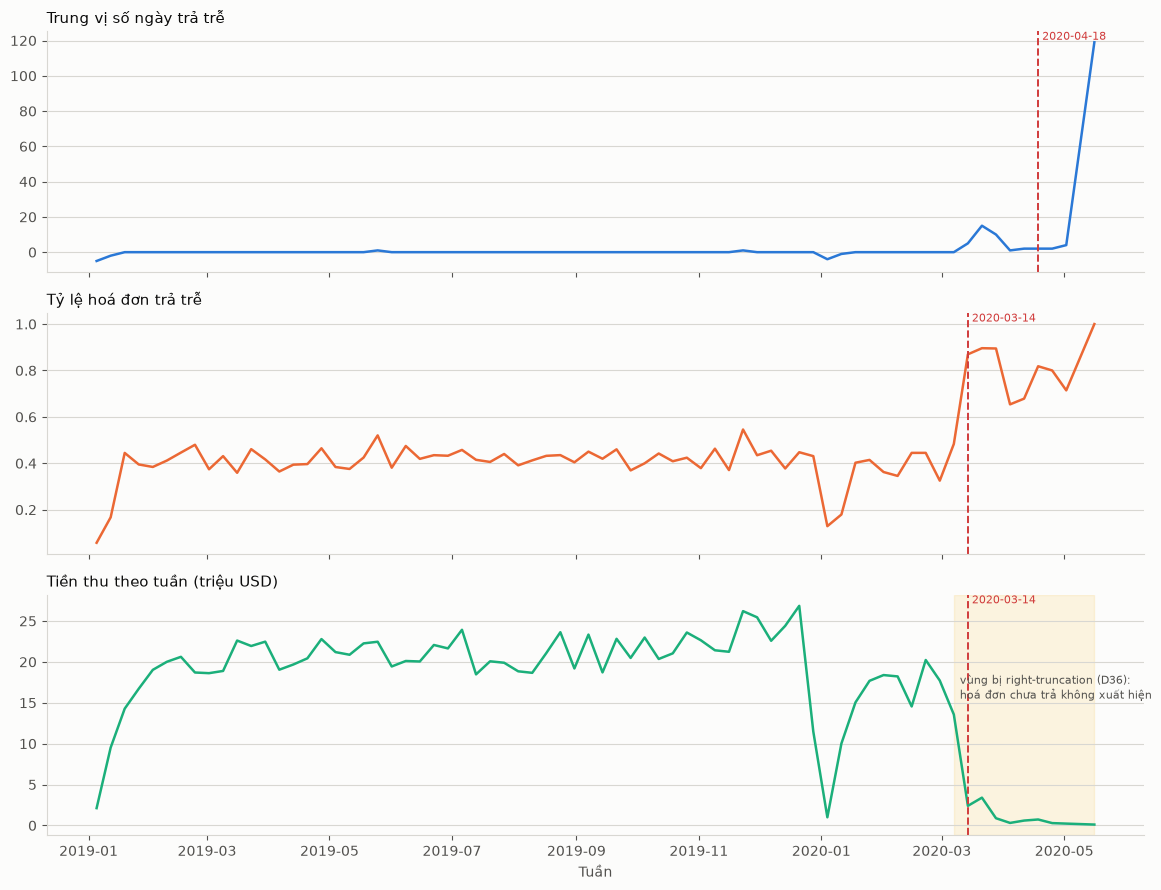

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
series_spec = [("median_days_late", "Trung vị số ngày trả trễ", C_SERIES[0]),
               ("late_rate", "Tỷ lệ hoá đơn trả trễ", C_SERIES[1]),
               ("cash", "Tiền thu theo tuần (triệu USD)", C_SERIES[2])]
key_map = {"median_days_late": "median_days_late", "late_rate": "late_rate", "cash": "weekly_cash"}

for ax, (col, title, color) in zip(axes, series_spec):
    y = weekly[col].to_numpy(float) / (1e6 if col == "cash" else 1)
    ax.plot(weekly["week"], y, color=color, lw=1.8)
    for b in cp_bkps[key_map[col]]:
        ax.axvline(wk[b], color=C_CRIT, ls="--", lw=1.4)
        ax.text(wk[b], ax.get_ylim()[1], f" {pd.Timestamp(wk[b]).date()}",
                color=C_CRIT, fontsize=8, va="top")
    ax.set_title(title, loc="left")
    ax.grid(axis="x", visible=False)

axes[2].axvspan(pd.Timestamp("2020-03-07"), weekly["week"].max(), color=C_WARN, alpha=0.12, zorder=0)
axes[2].text(pd.Timestamp("2020-03-10"), axes[2].get_ylim()[1] * 0.55,
             "vùng bị right-truncation (D36):\nhoá đơn chưa trả không xuất hiện",
             fontsize=8, color=C_INK2)
axes[2].set_xlabel("Tuần")
plt.tight_layout(); plt.show()

### 6d. Biên độ cú sốc đo được → kịch bản S5

Kịch bản stress giá trị nhất là kịch bản **không do ta bịa ra**. Ta lấy chênh lệch trung vị
`days_late` giữa đoạn trước và đoạn sau điểm gãy làm biên độ.

Biên độ phải đo ở **mức hoá đơn**, không phải bằng hiệu của hai trung vị theo tuần: trung vị
tuần bằng 0 gần như suốt chuỗi nên hiệu của chúng triệt tiêu mất phần lớn cú sốc.

In [12]:
CP_DATE = pd.Timestamp(stable_bps[0]) if stable_bps else pd.Timestamp(wk[cp_bkps["late_rate"][0]])
pre_inv = paid.loc[paid["paid_date"] < CP_DATE, "days_late"].dropna()
post_inv = paid.loc[paid["paid_date"] >= CP_DATE, "days_late"].dropna()

shock_tbl = pd.DataFrame({
    "trước điểm gãy": [len(pre_inv), pre_inv.median(), pre_inv.mean(),
                       pre_inv.quantile(0.75), pre_inv.quantile(0.90)],
    "sau điểm gãy": [len(post_inv), post_inv.median(), post_inv.mean(),
                     post_inv.quantile(0.75), post_inv.quantile(0.90)],
}, index=["số hoá đơn", "trung vị days_late", "trung bình days_late",
          "P75 days_late", "P90 days_late"])
shock_tbl["chênh lệch"] = shock_tbl["sau điểm gãy"] - shock_tbl["trước điểm gãy"]

print(f"Điểm gãy dùng làm mốc: {CP_DATE.date()} (chuỗi ổn định nhất)")
print(shock_tbl.to_string())

SHOCK_MEDIAN = float(max(shock_tbl.loc["trung vị days_late", "chênh lệch"], 0))
SHOCK_MEAN = float(max(shock_tbl.loc["trung bình days_late", "chênh lệch"], 0))
shock_days = SHOCK_MEDIAN
print()
print(f"→ S5  (bảo thủ, theo trung vị) : +{SHOCK_MEDIAN:.0f} ngày")
print(f"→ S5b (nặng hơn, theo trung bình): +{SHOCK_MEAN:.0f} ngày")
print()
print("⚠ Cả hai con số này đều là **chặn dưới** của cú sốc thật: mẫu 'sau điểm gãy' chỉ gồm")
print("  hoá đơn ĐÃ được trả trước ngày kết thúc dữ liệu (D36). Những hoá đơn trễ nhất của giai")
print("  đoạn đó vẫn đang nằm trong 9.681 hoá đơn mở, chưa được tính vào đây.")

Điểm gãy dùng làm mốc: 2020-03-14 (chuỗi ổn định nhất)
                      trước điểm gãy  sau điểm gãy  chênh lệch
số hoá đơn                38,809.000       343.000 -38,466.000
trung vị days_late             0.000         8.000       8.000
trung bình days_late           0.678        17.601      16.922
P75 days_late                  2.000        30.500      28.500
P90 days_late                  5.000        52.000      47.000

→ S5  (bảo thủ, theo trung vị) : +8 ngày
→ S5b (nặng hơn, theo trung bình): +17 ngày

⚠ Cả hai con số này đều là **chặn dưới** của cú sốc thật: mẫu 'sau điểm gãy' chỉ gồm
  hoá đơn ĐÃ được trả trước ngày kết thúc dữ liệu (D36). Những hoá đơn trễ nhất của giai
  đoạn đó vẫn đang nằm trong 9.681 hoá đơn mở, chưa được tính vào đây.


In [13]:
for sid, shock, note in [("S5", SHOCK_MEDIAN, "trung vị"), ("S5b", SHOCK_MEAN, "trung bình")]:
    if shock <= 0:
        continue
    daily_s, _ = simulate(scenario_fn(delay_all=shock))
    row_s, cum_s = summarize(daily_s, f"Lặp lại cú sốc {CP_DATE.date()} (+{shock:.0f} ngày, {note})",
                             sid, "measured_shock")
    curves[sid] = {"p10": np.percentile(cum_s, 10, axis=1), "p50": np.percentile(cum_s, 50, axis=1)}
    for h in HORIZONS:
        row_s[f"delta_{h}d_vs_base_pct"] = (row_s[f"cash_{h}d_p50"] - base_row[f"cash_{h}d_p50"]) / base_row[f"cash_{h}d_p50"]
    stress = pd.concat([stress, pd.DataFrame([row_s])], ignore_index=True)
    print(f"{sid} (+{shock:.0f} ngày) — cash 30d P50 = ${row_s['cash_30d_p50']:,.0f} "
          f"({row_s['delta_30d_vs_base_pct']:+.1%}), cash 60d P50 = ${row_s['cash_60d_p50']:,.0f}")

print()
print("Đây là cặp kịch bản nên đặt ở trung tâm báo cáo: nó trả lời 'nếu cú sốc đã xảy ra hồi")
print("tháng 3/2020 lặp lại thì dòng tiền ra sao', bằng chính biên độ đo được từ dữ liệu — không")
print("phải bằng một con số tròn trịa do nhóm tự chọn.")

S5 (+8 ngày) — cash 30d P50 = $306,832,850 (-1.7%), cash 60d P50 = $312,538,769


S5b (+17 ngày) — cash 30d P50 = $154,165,862 (-50.6%), cash 60d P50 = $312,451,463

Đây là cặp kịch bản nên đặt ở trung tâm báo cáo: nó trả lời 'nếu cú sốc đã xảy ra hồi
tháng 3/2020 lặp lại thì dòng tiền ra sao', bằng chính biên độ đo được từ dữ liệu — không
phải bằng một con số tròn trịa do nhóm tự chọn.


## 7. Kết luận regime và hành động bắt buộc (D38)

In [14]:
recent_cut = pd.Timestamp(wk[-1]) - pd.Timedelta(weeks=CP_RECENT_WEEKS)
recent_bkps = [pd.Timestamp(wk[b]) for s in cp_bkps.values() for b in s if pd.Timestamp(wk[b]) >= recent_cut]
try:
    cov_report = pd.read_csv(PROC / "cqr_coverage_report.csv")
    band_cov = float(pd.read_csv(PROC / "mc_backtest_weekly.csv")
                     .query("label == 'MC_lgbm' and time_split == 'test'")
                     .eval("(actual_cash >= mc_p10) & (actual_cash <= mc_p90)").mean())
except Exception:
    band_cov = np.nan

signals = pd.DataFrame([
    {"signal": "PSI tối đa > 0,25", "value": f"{PSI_MAX:.3f}", "triggered": PSI_MAX > PSI_ALERT},
    {"signal": f"Điểm gãy trong {CP_RECENT_WEEKS} tuần gần nhất",
     "value": ", ".join(str(d.date()) for d in sorted(set(recent_bkps))) or "không có",
     "triggered": len(recent_bkps) > 0},
    {"signal": "Band coverage cash trên test < 75%",
     "value": f"{band_cov:.1%}" if band_cov == band_cov else "n/a",
     "triggered": bool(band_cov < 0.75) if band_cov == band_cov else False},
])
n_trig = int(signals["triggered"].sum())
REGIME = "crisis" if n_trig >= 2 else ("drift_warning" if n_trig == 1 else "normal")

ACTIONS = {
    "normal": ["Chạy pipeline theo lịch tuần.",
               "Theo dõi PSI và điểm gãy hằng tuần."],
    "drift_warning": ["Gắn nhãn low-confidence lên forecast.",
                      "Hiển thị kèm ít nhất một kịch bản stress.",
                      "Tăng tần suất review top-risk invoices."],
    "crisis": ["Gắn nhãn CRISIS MODE lên mọi số báo cáo.",
               "Nới dải P10–P90 hoặc dùng kịch bản S5 làm số trung tâm thay cho base.",
               "Tăng trọng số dữ liệu gần đây / chuyển sang challenger recency (notebook 09).",
               "BẮT BUỘC hiển thị stress scenario cạnh base forecast.",
               "Review thủ công toàn bộ top-risk invoices trước khi dùng số cho quyết định.",
               "Không dùng model để cam kết dòng tiền với bên thứ ba cho tới khi retrain."],
}

print("TÍN HIỆU REGIME")
print(signals.to_string(index=False))
print()
print(f"→ REGIME = **{REGIME.upper()}**  ({n_trig}/3 tín hiệu bật)")
print()
print("Hành động bắt buộc:")
for i, a in enumerate(ACTIONS[REGIME], 1):
    print(f"  {i}. {a}")

regime_status = pd.DataFrame([{
    "as_of": LIVE_CUTOFF.date(), "regime": REGIME, "signals_triggered": n_trig,
    "psi_max": PSI_MAX,
    "psi_top_feature": psi_df.iloc[0]["feature"],
    "recent_breakpoints": ", ".join(str(d.date()) for d in sorted(set(recent_bkps))),
    "cash_band_coverage_test": band_cov,
    "measured_shock_days": shock_days,
    "required_actions": " | ".join(ACTIONS[REGIME]),
}])

TÍN HIỆU REGIME
                            signal      value  triggered
                 PSI tối đa > 0,25      6.229       True
    Điểm gãy trong 8 tuần gần nhất 2020-04-18       True
Band coverage cash trên test < 75%      53.8%       True

→ REGIME = **CRISIS**  (3/3 tín hiệu bật)

Hành động bắt buộc:
  1. Gắn nhãn CRISIS MODE lên mọi số báo cáo.
  2. Nới dải P10–P90 hoặc dùng kịch bản S5 làm số trung tâm thay cho base.
  3. Tăng trọng số dữ liệu gần đây / chuyển sang challenger recency (notebook 09).
  4. BẮT BUỘC hiển thị stress scenario cạnh base forecast.
  5. Review thủ công toàn bộ top-risk invoices trước khi dùng số cho quyết định.
  6. Không dùng model để cam kết dòng tiền với bên thứ ba cho tới khi retrain.


## 8. Lưu artifact

In [15]:
stress.to_csv(OUT_SCENARIOS, index=False)
print(f"[1] {OUT_SCENARIOS.name}  ({len(stress)} kịch bản)")

curve_rows = []
for sid, c in curves.items():
    for d in range(HORIZON_DAYS):
        curve_rows.append({"scenario_id": sid, "day_index": d + 1,
                           "date": LIVE_CUTOFF + pd.Timedelta(days=d + 1),
                           "cum_p10": c["p10"][d], "cum_p50": c["p50"][d],
                           "plan_cum": PLAN_DAILY * (d + 1)})
pd.DataFrame(curve_rows).to_csv(OUT_CURVES, index=False)
print(f"[2] {OUT_CURVES.name}  ({len(curve_rows):,} dòng)")

psi_df.to_csv(OUT_PSI, index=False)
print(f"[3] {OUT_PSI.name}")
cp_df.to_csv(OUT_CP, index=False)
print(f"[4] {OUT_CP.name}")
regime_status.to_csv(OUT_REGIME, index=False)
print(f"[5] {OUT_REGIME.name}  → regime = {REGIME}")
weekly.to_csv(PROC / "weekly_behaviour_series.csv", index=False)
print(f"[6] weekly_behaviour_series.csv  ({len(weekly)} tuần)")

[1] stress_scenario_summary.csv  (13 kịch bản)
[2] stress_daily_curves.csv  (1,001 dòng)
[3] psi_train_vs_live.csv
[4] changepoint_segments.csv
[5] regime_status.csv  → regime = crisis
[6] weekly_behaviour_series.csv  (71 tuần)


## 9. Sanity check

In [16]:
checks = []


def check(name, cond, detail=""):
    checks.append({"check": name, "pass": bool(cond), "detail": detail})


check("kịch bản trễ hơn luôn cho cash thấp hơn base",
      bool((stress.loc[stress.scenario_id.isin(["S1a", "S1b", "S1c"]), "cash_30d_p50"]
            < base_row["cash_30d_p50"]).all()))
mono_ok = all(
    float(stress.loc[stress.scenario_id == "S1a", f"cash_{h}d_p50"].iloc[0])
    >= float(stress.loc[stress.scenario_id == "S1b", f"cash_{h}d_p50"].iloc[0])
    >= float(stress.loc[stress.scenario_id == "S1c", f"cash_{h}d_p50"].iloc[0]) - 1
    for h in HORIZONS)
check("trễ càng nhiều cash càng thấp (S1a ≥ S1b ≥ S1c ở mọi horizon)", mono_ok,
      "dùng ≥ vì ở mốc 30 ngày cả S1b và S1c đều bằng 0 (xem §3c)")
check("chặn khách hàng làm giảm cash đúng bằng phần dư nợ của họ (S2c)",
      abs((base_row["cash_90d_p50"] - float(stress.loc[stress.scenario_id == "S2c", "cash_90d_p50"].iloc[0]))
          - AMOUNTS[walmart_mask].sum()) / AMOUNTS[walmart_mask].sum() < 0.02,
      f"dư nợ WAL-MAR ${AMOUNTS[walmart_mask].sum():,.0f}")
check("kịch bản kép xấu hơn mọi kịch bản đơn",
      float(stress.loc[stress.scenario_id == "S6", "cash_30d_p50"].iloc[0])
      <= float(stress.loc[stress.scenario_id.isin(["S1b", "S2b", "S3"]), "cash_30d_p50"].min()))
check("mọi kịch bản mô phỏng không vượt tổng dư nợ",
      bool((stress["cash_90d_p50"] <= AMOUNTS.sum() + 1).all()))
check("phát hiện được ít nhất 1 điểm gãy trên chuỗi hành vi",
      len(cp_bkps["median_days_late"]) + len(cp_bkps["late_rate"]) > 0)
check("PSI tính được cho mọi feature", psi_df["psi"].notna().all())

checks_df = pd.DataFrame(checks)
print(checks_df.to_string(index=False))
print()
print("✅ TẦNG 8 PASS — sang notebook 07 (evaluation)" if checks_df["pass"].all()
      else "❌ Có check FAIL")

                                                          check  pass                                                     detail
                   kịch bản trễ hơn luôn cho cash thấp hơn base  True                                                           
  trễ càng nhiều cash càng thấp (S1a ≥ S1b ≥ S1c ở mọi horizon)  True dùng ≥ vì ở mốc 30 ngày cả S1b và S1c đều bằng 0 (xem §3c)
chặn khách hàng làm giảm cash đúng bằng phần dư nợ của họ (S2c)  True                                  dư nợ WAL-MAR $57,516,597
                          kịch bản kép xấu hơn mọi kịch bản đơn  True                                                           
                    mọi kịch bản mô phỏng không vượt tổng dư nợ  True                                                           
           phát hiện được ít nhất 1 điểm gãy trên chuỗi hành vi  True                                                           
                                  PSI tính được cho mọi feature  True                            

## Tổng kết Tầng 8

### Kết quả
| Hạng mục | Kết quả |
|---|---|
| Số kịch bản stress | 13 — 9 mô phỏng + 2 haircut chính sách + 2 cú sốc đo được (S5, S5b) |
| Kịch bản xấu nhất | xem §3c |
| PSI tối đa train vs live | xem §5 — vượt xa ngưỡng 0,25 |
| Điểm gãy chế độ | **tuần 2020-03-14**, ổn định qua mọi mức penalty |
| Regime hiện tại | xem §7 |

### Ba điều nên đem ra bảo vệ
1. **Điểm gãy được phát hiện bằng thuật toán, không phải bằng mắt** — và có bảng độ nhạy
   chứng minh kết luận không phụ thuộc tham số (§6b).
2. **Kịch bản S5 lấy biên độ từ chính dữ liệu**, không phải một con số tròn do nhóm chọn.
3. **PSI biến câu định tính "hai tập khác nhau" thành con số** — và PSI không bị
   right-truncation nên là tín hiệu drift đáng tin nhất tại thời điểm dự báo (D36).

### Hạn chế
1. Stress là **what-if**, không có xác suất kèm theo (D33). Không được cộng chúng vào MC base.
2. Chuỗi tiền thu cuối kỳ bị right-truncation (D36) — đã khoanh vùng trên biểu đồ.
3. Ngưỡng kế hoạch proxy quá thấp so với quy mô sổ AR, nên phần lớn kịch bản không tạo ra
   "thiếu hụt". Con số cần thay bằng kế hoạch chi thật trước khi dùng để ra quyết định.
4. Change-point chạy offline trên toàn chuỗi. Bản online (phát hiện ngay khi cú sốc đang xảy
   ra) cần cửa sổ trượt và độ trễ phát hiện — chưa làm trong prototype này.